# Swin3D Crime Detection Model - Violence/Theft/Normal Classification
## Swin3D-T Transformer with Full Training Pipeline and Performance Visualization

## 1. Import Required Libraries

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import gc
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.9.0+cu126
Torchvision version: 0.24.0+cu126
CUDA available: True


## 2. Define Dataset Paths and Classes

In [2]:
RWF       = "/kaggle/input/datasets/daniazehra/rwf-2000/RWF-2000"
UCF_CRIME = "/kaggle/input/datasets/alirakhmaev/ucf-crime-full"
CAMNUVEOM = "/kaggle/input/datasets/mohamedelattar02/camnuveom2/camnuveom/videos/samples/training"

MAIN_CLASSES = ['violence', 'theft', 'normal']

UCF_TO_MAIN_CLASS = {
    'Shoplifting': 'theft',
    'Stealing':    'theft',
    'Robbery':     'theft',
    'Burglary':    'theft',
    'Normal':      'normal',
}

NUM_FRAMES = 16
IMG_SIZE   = 224

print(f"Main Classes: {MAIN_CLASSES}")
print(f"Number of Classes: {len(MAIN_CLASSES)}")

Main Classes: ['violence', 'theft', 'normal']
Number of Classes: 3


## 3. Data Loading Functions

In [3]:
def load_camnuveom():
    rows = []
    for cls in ["anomaly", "normal"]:
        class_dir = os.path.join(CAMNUVEOM, cls)
        if not os.path.exists(class_dir): continue
        main_label = "theft" if cls == "anomaly" else "normal"
        for video_path in glob.glob(os.path.join(class_dir, "*.mp4")):
            rows.append({'clip_path': video_path, 'main_label': main_label,
                         'sub_label': main_label, 'dataset': 'camnuveon',
                         'original_class': cls, 'split': 'unknown'})
    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from CAMNUVEON")
    return df

def load_rwf():
    rows = []
    for split in ["train", "val"]:
        for cls in ["Fight", "NonFight"]:
            class_dir = os.path.join(RWF, split, cls)
            if not os.path.exists(class_dir): continue
            main_label = "violence" if cls == "Fight" else "normal"
            for video_path in glob.glob(os.path.join(class_dir, "*.avi")):
                rows.append({'clip_path': video_path, 'main_label': main_label,
                             'sub_label': main_label, 'dataset': 'RWF-2000',
                             'original_class': cls, 'split': split})
    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from RWF-2000")
    return df

def load_ucf():
    if not os.path.exists(UCF_CRIME): return None
    class_folders = [d for d in os.listdir(UCF_CRIME) if os.path.isdir(os.path.join(UCF_CRIME, d))]
    rows = []
    for class_name in class_folders:
        class_path = os.path.join(UCF_CRIME, class_name)
        main_label = UCF_TO_MAIN_CLASS.get(class_name)
        if main_label is None: continue
        videos = glob.glob(os.path.join(class_path, "*.mp4")) + glob.glob(os.path.join(class_path, "*.avi"))
        for video_path in videos:
            rows.append({'clip_path': video_path, 'main_label': main_label,
                         'sub_label': class_name.lower(), 'dataset': 'UCF-Crime',
                         'original_class': class_name, 'split': 'unknown'})
    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from UCF-Crime")
    return df

## 4. Load and Merge Datasets

In [4]:
print("\n" + "="*60 + "\nLOADING DATASETS\n" + "="*60)
rwf_df = load_rwf()
ucf_df = load_ucf()
cam_df = load_camnuveom()

df = pd.concat([rwf_df, ucf_df, cam_df], ignore_index=True)
df = df[df['main_label'].isin(MAIN_CLASSES)].copy()

print(f"\nTotal videos loaded: {len(df)}")
print("\n" + "="*60 + "\nDATASET DISTRIBUTION\n" + "="*60)
for cls in MAIN_CLASSES:
    count = len(df[df['main_label'] == cls])
    print(f"  {cls}: {count:4d} videos ({count / len(df) * 100:5.1f}%)")


LOADING DATASETS
✓ Loaded 2000 videos from RWF-2000
✓ Loaded 400 videos from UCF-Crime
✓ Loaded 874 videos from CAMNUVEON

Total videos loaded: 3274

DATASET DISTRIBUTION
  violence: 1000 videos ( 30.5%)
  theft:  837 videos ( 25.6%)
  normal: 1437 videos ( 43.9%)


## 5. Swin3D Dataset Class

In [5]:
class Swin3DCrimeDetectionDataset(Dataset):
    def __init__(self, dataframe, num_frames=16, img_size=224, is_train=True):
        self.dataframe = dataframe.reset_index(drop=True)
        self.num_frames = num_frames
        self.img_size = img_size
        self.is_train = is_train
        self.label_to_idx = {label: idx for idx, label in enumerate(MAIN_CLASSES)}
        self.idx_to_label = {idx: label for label, idx in self.label_to_idx.items()}

    def __len__(self):
        return len(self.dataframe)

    def extract_frames(self, video_path):
        try:
            cap = cv2.VideoCapture(video_path)
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if total_frames < 1:
                cap.release(); return None

            if 'UCF-Crime' in video_path:
                start_frame = max(0, total_frames // 4)
                end_frame   = min(total_frames, 3 * total_frames // 4)
            else:
                start_frame, end_frame = 0, total_frames

            if end_frame <= start_frame:
                indices = [0] * self.num_frames
            else:
                indices = np.linspace(start_frame, end_frame - 1, self.num_frames, dtype=int)

            frames = []
            for idx in indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
                ret, frame = cap.read()
                if ret:
                    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                    frame = cv2.resize(frame, (self.img_size, self.img_size))
                    frames.append(frame.astype(np.float32) / 255.0)
                else:
                    frames.append(np.zeros((self.img_size, self.img_size, 3), dtype=np.float32))
            cap.release()
            if len(frames) == 0: return None

            frames = np.stack(frames, axis=0)
            frames = np.transpose(frames, (3, 0, 1, 2))
            return frames
        except:
            return None

    def __getitem__(self, idx):
        video_path = self.dataframe.loc[idx, 'clip_path']
        main_label = self.dataframe.loc[idx, 'main_label']
        frames = self.extract_frames(video_path)

        if frames is None:
            frames_tensor = torch.zeros((3, self.num_frames, self.img_size, self.img_size))
            label_idx = self.label_to_idx['normal']
        else:
            frames_tensor = torch.from_numpy(frames).float()
            mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1, 1)
            std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1, 1)
            frames_tensor = (frames_tensor - mean) / std
            label_idx = self.label_to_idx[main_label]
        return frames_tensor, label_idx, video_path

## 6. Create Data Splits (15% Test)

In [6]:
df = df.sample(frac=1).reset_index(drop=True)
NUM_CLASSES = len(MAIN_CLASSES)

train_val, test = train_test_split(
    df, test_size=0.15, stratify=df['main_label'], random_state=42
)
print(f"Train+Val: {len(train_val)} samples")
print(f"Test     : {len(test)} samples")

Train+Val: 2782 samples
Test     : 492 samples


## 7. Single Train/Val Split (80/20) Setup

In [7]:
BATCH_SIZE  = 4
NUM_WORKERS = 2

print("\n" + "="*60 + "\nSINGLE TRAIN/VAL SPLIT\n" + "="*60)
train_df, val_df = train_test_split(
    train_val, test_size=0.20, stratify=train_val['main_label'], random_state=38
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
print(f"  Train: {len(train_df)} | Val: {len(val_df)}")

train_dataset = Swin3DCrimeDetectionDataset(train_df, num_frames=NUM_FRAMES, img_size=IMG_SIZE, is_train=True)
val_dataset   = Swin3DCrimeDetectionDataset(val_df,   num_frames=NUM_FRAMES, img_size=IMG_SIZE, is_train=False)
test_dataset  = Swin3DCrimeDetectionDataset(test,     num_frames=NUM_FRAMES, img_size=IMG_SIZE, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)



SINGLE TRAIN/VAL SPLIT
  Train: 2225 | Val: 557


## 8. Swin3D Model Creation

In [8]:
print("\n" + "="*60 + "\nSWIN3D MODEL CREATION\n" + "="*60)

def swin3d_for_3class(num_classes=3):
    try:
        from torchvision.models.video import swin3d_t
        model = swin3d_t(weights='KINETICS400_V1')
        if hasattr(model, 'head'):
            if isinstance(model.head, nn.Sequential):
                in_features = model.head[1].in_features
                model.head = nn.Sequential(model.head[0], nn.Linear(in_features, num_classes))
            else:
                in_features = model.head.in_features
                model.head = nn.Linear(in_features, num_classes)
        else:
            if hasattr(model, 'fc'):
                model.fc = nn.Linear(model.fc.in_features, num_classes)
            elif hasattr(model, 'classifier'):
                model.classifier = nn.Linear(model.classifier.in_features, num_classes)
        return model
    except Exception as e:
        print(f"Error loading Swin3D: {e}")
        class Simple3DCNN(nn.Module):
            def __init__(self, num_classes=3):
                super().__init__()
                self.conv1 = nn.Conv3d(3, 32, (3,3,3), padding=1)
                self.pool1 = nn.MaxPool3d((1,2,2))
                self.conv2 = nn.Conv3d(32, 64, (3,3,3), padding=1)
                self.pool2 = nn.MaxPool3d((2,2,2))
                self.conv3 = nn.Conv3d(64, 128, (3,3,3), padding=1)
                self.pool3 = nn.MaxPool3d((2,2,2))
                self.fc1 = nn.Linear(128 * 2 * 14 * 14, 512)
                self.dropout = nn.Dropout(0.5)
                self.fc2 = nn.Linear(512, num_classes)
            def forward(self, x):
                x = self.pool1(torch.relu(self.conv1(x)))
                x = self.pool2(torch.relu(self.conv2(x)))
                x = self.pool3(torch.relu(self.conv3(x)))
                x = x.view(x.size(0), -1)
                return self.fc2(self.dropout(torch.relu(self.fc1(x))))
        return Simple3DCNN(num_classes)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

model = swin3d_for_3class(NUM_CLASSES).to(device)
print(f"\n✓ Model: {model.__class__.__name__}")
print(f"  Parameters: {sum(p.numel() for p in model.parameters()):,}")


SWIN3D MODEL CREATION
Using device: cuda
Downloading: "https://download.pytorch.org/models/swin3d_t-7615ae03.pth" to /root/.cache/torch/hub/checkpoints/swin3d_t-7615ae03.pth


100%|██████████| 122M/122M [00:02<00:00, 47.1MB/s] 



✓ Model: SwinTransformer3d
  Parameters: 27,852,777


## 9. Training Functions

In [9]:
def train_epoch(model, loader, optimizer, criterion, device, epoch):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    class_correct = {c: 0 for c in MAIN_CLASSES}
    class_total   = {c: 0 for c in MAIN_CLASSES}
    pbar = tqdm(loader, desc=f'Train Epoch {epoch}')

    for batch_idx, (inputs, labels, _) in enumerate(pbar):
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        _, pred = outputs.max(1)
        total += labels.size(0)
        correct += pred.eq(labels).sum().item()
        total_loss += loss.item()
        
        for i in range(len(labels)):
            c = MAIN_CLASSES[labels[i].item()]
            class_total[c] += 1
            if pred[i] == labels[i]: class_correct[c] += 1
            
        pbar.set_postfix({'Loss': f'{total_loss/(batch_idx+1):.4f}', 'Acc': f'{100.*correct/total:.1f}%'})

    print("  Per-class training accuracy:")
    for c in MAIN_CLASSES:
        if class_total[c] > 0: print(f"    {c}: {100.*class_correct[c]/class_total[c]:.1f}%")
    return total_loss/len(loader), 100.*correct/total

def validate(model, loader, criterion, device, mode='val'):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    class_correct, class_total = {c: 0 for c in MAIN_CLASSES}, {c: 0 for c in MAIN_CLASSES}

    with torch.no_grad():
        for inputs, labels, _ in tqdm(loader, desc=f'{mode.capitalize()} Eval'):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            _, pred = outputs.max(1)
            total += labels.size(0)
            correct += pred.eq(labels).sum().item()
            total_loss += loss.item()
            
            for i in range(len(labels)):
                c = MAIN_CLASSES[labels[i].item()]
                class_total[c] += 1
                if pred[i] == labels[i]: class_correct[c] += 1
            
            all_preds.extend(pred.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = 100.*correct/total
    print(f"  {mode.capitalize()} Loss: {total_loss/len(loader):.4f}, Accuracy: {acc:.1f}%")
    for c in MAIN_CLASSES:
        if class_total[c] > 0: print(f"    {c}: {100.*class_correct[c]/class_total[c]:.1f}%")
    return total_loss/len(loader), acc, all_preds, all_labels

## 10. Initialize Loss Function

In [10]:
criterion = nn.CrossEntropyLoss()
print(f"Loss function: {criterion.__class__.__name__}")

Loss function: CrossEntropyLoss


## 11. Training Loop (Single Split)

In [11]:
EPOCHS = 10
print("\n" + "="*60 + "\nTRAINING SWIN3D MODEL\n" + "="*60)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

best_val_acc = 0
patience = 3
patience_ctr = 0
tr_losses, vl_losses, tr_accs, vl_accs = [], [], [], []

for epoch in range(1, EPOCHS + 1):
    tl, ta = train_epoch(model, train_loader, optimizer, criterion, device, epoch)
    vl, va, _, _ = validate(model, val_loader, criterion, device, 'val')
    tr_losses.append(tl); tr_accs.append(ta)
    vl_losses.append(vl); vl_accs.append(va)
    
    if va > best_val_acc:
        best_val_acc = va
        patience_ctr = 0
        torch.save(model.state_dict(), "/kaggle/working/best_swin3d.pth")
        print(f"  ✓ Best model saved (Val Acc: {va:.2f}%)")
    else:
        patience_ctr += 1
        print(f"  ✗ No improvement ({patience_ctr}/{patience})")
        if patience_ctr >= patience:
            print("  EARLY STOPPING TRIGGERED")
            break
    scheduler.step()
    
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()


TRAINING SWIN3D MODEL


Train Epoch 1: 100%|██████████| 556/556 [10:01<00:00,  1.08s/it, Loss=0.7334, Acc=66.5%]


  Per-class training accuracy:
    violence: 68.7%
    theft: 52.5%
    normal: 73.1%


Val Eval: 100%|██████████| 140/140 [02:35<00:00,  1.11s/it]


  Val Loss: 0.5363, Accuracy: 79.4%
    violence: 85.3%
    theft: 88.0%
    normal: 70.2%
  ✓ Best model saved (Val Acc: 79.35%)


...

  Val Loss: 0.4470, Accuracy: 88.0%
    violence: 88.8%
    theft: 87.3%
    normal: 87.8%
  ✗ No improvement (2/3)


Train Epoch 10: 100%|██████████| 556/556 [09:15<00:00,  1.00it/s, Loss=0.0129, Acc=99.6%]


  Per-class training accuracy:
    violence: 99.7%
    theft: 99.5%
    normal: 99.6%


Val Eval: 100%|██████████| 140/140 [02:23<00:00,  1.02s/it]

  Val Loss: 0.4478, Accuracy: 88.2%
    violence: 89.4%
    theft: 87.3%
    normal: 87.8%
  ✗ No improvement (3/3)
  EARLY STOPPING TRIGGERED


## 12. Evaluate on Test Set

In [12]:
print("\n" + "="*60 + "\nTEST SET EVALUATION\n" + "="*60)

best_model = swin3d_for_3class(NUM_CLASSES)
best_model.load_state_dict(torch.load("/kaggle/working/best_swin3d.pth"))
best_model = best_model.to(device)

test_loss, test_acc, test_preds, test_labels = validate(best_model, test_loader, criterion, device, 'test')
print(f"\nFinal Test Accuracy: {test_acc:.2f}%")


TEST SET EVALUATION


Test Eval: 100%|██████████| 123/123 [02:09<00:00,  1.05s/it]

  Test Loss: 0.5659, Accuracy: 84.8%
    violence: 90.0%
    theft: 82.5%
    normal: 82.4%

Final Test Accuracy: 84.76%


## 13. Detailed Performance Metrics

In [13]:
print("\n" + "="*60 + "\nCLASSIFICATION REPORT\n" + "="*60)
print(classification_report(test_labels, test_preds, target_names=MAIN_CLASSES, digits=4))


CLASSIFICATION REPORT
              precision    recall  f1-score   support

    violence     0.8084    0.9000    0.8517       150
       theft     0.8387    0.8254    0.8320       126
      normal     0.8856    0.8241    0.8537       216

    accuracy                         0.8476       492
   macro avg     0.8442    0.8498    0.8458       492
weighted avg     0.8500    0.8476    0.8476       492



## 14. Confusion Matrix Visualization

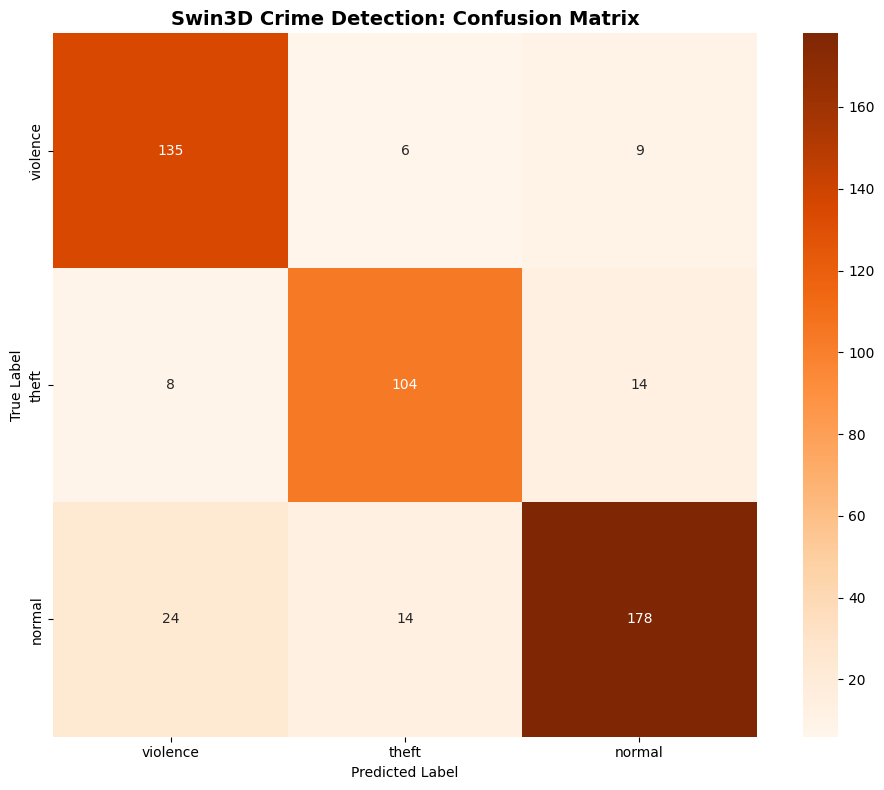

In [14]:
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=MAIN_CLASSES, yticklabels=MAIN_CLASSES, square=True)
plt.title('Swin3D Crime Detection: Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label'); plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('/kaggle/working/swin3d_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

## 15. Training History Visualization

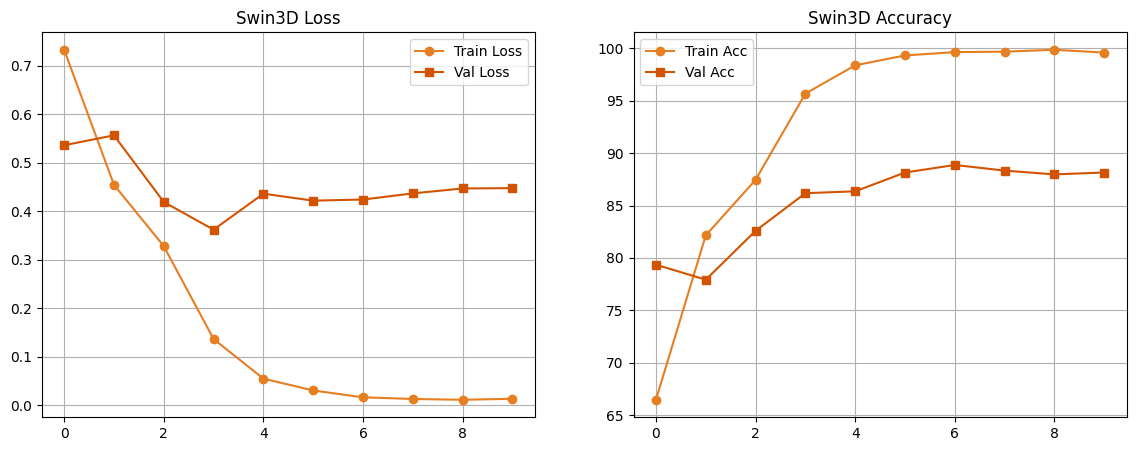

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(tr_losses, 'o-', label='Train Loss', color='#e67e22')
axes[0].plot(vl_losses, 's-', label='Val Loss',   color='#d35400')
axes[0].set_title('Swin3D Loss'); axes[0].grid(True); axes[0].legend()

axes[1].plot(tr_accs, 'o-', label='Train Acc', color='#e67e22')
axes[1].plot(vl_accs, 's-', label='Val Acc',   color='#d35400')
axes[1].set_title('Swin3D Accuracy'); axes[1].grid(True); axes[1].legend()
plt.show()

## 16. Benchmark Summary

In [16]:
f1   = f1_score(test_labels, test_preds, average='macro')
prec = precision_score(test_labels, test_preds, average='macro')
rec  = recall_score(test_labels, test_preds, average='macro')

print("\n" + "="*60 + "\nSWIN3D BENCHMARK RESULTS\n" + "="*60)
print(f"  Model            : Swin3D-T")
print(f"  Frames per clip  : {NUM_FRAMES}")
print(f"  Image size       : {IMG_SIZE}x{IMG_SIZE}")
print(f"  Epochs           : {EPOCHS}")
print(f"  Best Val Acc     : {best_val_acc:.2f}%")
print(f"  Test Accuracy    : {test_acc:.2f}%")
print(f"  Macro F1-Score   : {f1:.4f}")
print(f"  Macro Precision  : {prec:.4f}")
print(f"  Macro Recall     : {rec:.4f}")
print("="*60)


SWIN3D BENCHMARK RESULTS
  Model            : Swin3D-T
  Frames per clip  : 16
  Image size       : 224x224
  Epochs           : 10
  Best Val Acc     : 88.87%
  Test Accuracy    : 84.76%
  Macro F1-Score   : 0.8458
  Macro Precision  : 0.8442
  Macro Recall     : 0.8498
